In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
!nvidia-smi

import torch

print("\nPyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU count:", torch.cuda.device_count())

Tue Nov 17 08:41:02 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os

print("Available input datasets:\n")

for item in os.listdir("/kaggle/input"):
    print(item)
    print("Path:", os.path.join("/kaggle/input", item))

Available input datasets:

datasets
Path: /kaggle/input/datasets


In [3]:
import os

DATASET_PATH = "/kaggle/input/datasets"

for root, dirs, files in os.walk(DATASET_PATH):
    level = root.replace(DATASET_PATH, "").count(os.sep)

    if level > 3:
        dirs[:] = []
        continue

    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:5]:
        print(f"{indent}    {file}")

    if len(files) > 5:
        print(f"{indent}    ... and {len(files)-5} more files")

datasets/
    vedantshingote28/
        road-vision-ai-dataset/
            README.dataset.txt
            README.roboflow.txt
            data.yaml
            test/
            train/
            valid/


In [4]:
import os
import yaml

DATASET_PATH = "/kaggle/input/datasets/vedantshingote28/road-vision-ai-dataset"

# Check folder structure and counts
for split in ["train", "valid", "test"]:
    image_dir = os.path.join(DATASET_PATH, split, "images")
    label_dir = os.path.join(DATASET_PATH, split, "labels")

    images = os.listdir(image_dir)
    labels = [f for f in os.listdir(label_dir) if f.endswith(".txt")]

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))

# Read original YAML
yaml_path = os.path.join(DATASET_PATH, "data.yaml")

print("\nORIGINAL DATA.YAML:")
with open(yaml_path, "r") as f:
    print(yaml.safe_load(f))


TRAIN
Images: 16002
Labels: 16002

VALID
Images: 1524
Labels: 1524

TEST
Images: 757
Labels: 757

ORIGINAL DATA.YAML:
{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 8, 'names': ['Bulldozer', 'Dump Truck', 'Excavator', 'Grader', 'Loader', 'Mixer Truck', 'Mobile Crane', 'Roller'], 'roboflow': {'workspace': 'capstone-lkzgq', 'project': 'construction-vehicle-detection-pxc7c', 'version': 2, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/capstone-lkzgq/construction-vehicle-detection-pxc7c/dataset/2'}}


In [5]:
!pip install -q ultralytics

In [6]:
import ultralytics
import torch

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics: 8.4.215
PyTorch: 2.11.0+cu130
CUDA available: True
GPU count: 2


In [7]:
import yaml
import os

DATASET_PATH = "/kaggle/input/datasets/vedantshingote28/road-vision-ai-dataset"

data = {
    "path": DATASET_PATH,
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 8,
    "names": [
        "Bulldozer",
        "Dump Truck",
        "Excavator",
        "Grader",
        "Loader",
        "Mixer Truck",
        "Mobile Crane",
        "Roller"
    ]
}

yaml_path = "/kaggle/working/data.yaml"

with open(yaml_path, "w") as f:
    yaml.safe_dump(data, f, sort_keys=False)

print("Kaggle YAML created successfully!")
print(open(yaml_path).read())

Kaggle YAML created successfully!
path: /kaggle/input/datasets/vedantshingote28/road-vision-ai-dataset
train: train/images
val: valid/images
test: test/images
nc: 8
names:
- Bulldozer
- Dump Truck
- Excavator
- Grader
- Loader
- Mixer Truck
- Mobile Crane
- Roller



In [8]:
from ultralytics.data.utils import check_det_dataset

data = check_det_dataset("/kaggle/working/data.yaml")

print("Dataset loaded successfully!")

print("\nTraining path:", data["train"])
print("Validation path:", data["val"])
print("Test path:", data["test"])

print("\nNumber of classes:", data["nc"])
print("Class names:", data["names"])

Dataset loaded successfully!

Training path: /kaggle/input/datasets/vedantshingote28/road-vision-ai-dataset/train/images
Validation path: /kaggle/input/datasets/vedantshingote28/road-vision-ai-dataset/valid/images
Test path: /kaggle/input/datasets/vedantshingote28/road-vision-ai-dataset/test/images

Number of classes: 8
Class names: {0: 'Bulldozer', 1: 'Dump Truck', 2: 'Excavator', 3: 'Grader', 4: 'Loader', 5: 'Mixer Truck', 6: 'Mobile Crane', 7: 'Roller'}


In [9]:
from ultralytics import YOLO
import torch

# Check available GPUs
print("Available GPUs:", torch.cuda.device_count())

# Load pretrained YOLO11 Nano model
model = YOLO("yolo11n.pt")

print("YOLO11n model loaded successfully!")

Available GPUs: 2
YOLO11n model loaded successfully!


In [10]:
# Training configuration

EPOCHS = 50
IMAGE_SIZE = 640
BATCH_SIZE = 16
PATIENCE = 10
GPU_DEVICE = 0

print("Training Configuration")
print("----------------------")
print("Model: YOLO11n")
print("Epochs:", EPOCHS)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Patience:", PATIENCE)
print("GPU:", GPU_DEVICE)

Training Configuration
----------------------
Model: YOLO11n
Epochs: 50
Image size: 640
Batch size: 16
Patience: 10
GPU: 0


In [12]:
!df -h /kaggle/working

Filesystem      Size  Used Avail Use% Mounted on
/dev/loop2       20G  5.5M   20G   1% /kaggle/working


In [14]:
import os
import shutil
from tqdm.notebook import tqdm

SOURCE = "/kaggle/input/datasets/vedantshingote28/road-vision-ai-dataset"
DESTINATION = "/kaggle/working/Dataset"

# Remove incomplete copy, if any
if os.path.exists(DESTINATION):
    shutil.rmtree(DESTINATION)

# Count total files
total_files = sum(
    len(files)
    for _, _, files in os.walk(SOURCE)
)

print("Total files to copy:", total_files)

# Copy with progress bar
with tqdm(total=total_files, desc="Copying dataset", unit="file") as pbar:
    for root, dirs, files in os.walk(SOURCE):

        relative_path = os.path.relpath(root, SOURCE)
        destination_folder = os.path.join(DESTINATION, relative_path)

        os.makedirs(destination_folder, exist_ok=True)

        for file in files:
            source_file = os.path.join(root, file)
            destination_file = os.path.join(destination_folder, file)

            shutil.copy2(source_file, destination_file)

            pbar.update(1)

print("\nDataset copied successfully!")

print("Train images:", len(os.listdir(DESTINATION + "/train/images")))
print("Validation images:", len(os.listdir(DESTINATION + "/valid/images")))
print("Test images:", len(os.listdir(DESTINATION + "/test/images")))

Total files to copy: 36569


Copying dataset:   0%|          | 0/36569 [00:00<?, ?file/s]


Dataset copied successfully!
Train images: 16002
Validation images: 1524
Test images: 757


In [15]:
import yaml

DATASET_PATH = "/kaggle/working/Dataset"

data = {
    "path": DATASET_PATH,
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 8,
    "names": [
        "Bulldozer",
        "Dump Truck",
        "Excavator",
        "Grader",
        "Loader",
        "Mixer Truck",
        "Mobile Crane",
        "Roller"
    ]
}

yaml_path = "/kaggle/working/data.yaml"

with open(yaml_path, "w") as f:
    yaml.safe_dump(data, f, sort_keys=False)

print("Updated YAML successfully!")
print(open(yaml_path).read())

Updated YAML successfully!
path: /kaggle/working/Dataset
train: train/images
val: valid/images
test: test/images
nc: 8
names:
- Bulldozer
- Dump Truck
- Excavator
- Grader
- Loader
- Mixer Truck
- Mobile Crane
- Roller



In [16]:
from ultralytics.data.utils import check_det_dataset

data = check_det_dataset("/kaggle/working/data.yaml")

print("Local dataset loaded successfully!")

print("\nTraining path:", data["train"])
print("Validation path:", data["val"])
print("Test path:", data["test"])

print("\nClasses:", data["names"])
print("Number of classes:", data["nc"])

Local dataset loaded successfully!

Training path: /kaggle/working/Dataset/train/images
Validation path: /kaggle/working/Dataset/valid/images
Test path: /kaggle/working/Dataset/test/images

Classes: {0: 'Bulldozer', 1: 'Dump Truck', 2: 'Excavator', 3: 'Grader', 4: 'Loader', 5: 'Mixer Truck', 6: 'Mobile Crane', 7: 'Roller'}
Number of classes: 8


In [ ]:
# Start

In [3]:
!pip install -q ultralytics

In [9]:
from ultralytics import YOLO

# Load our trained model
model = YOLO("/kaggle/input/models/vedantshingote28/road-vision-v1/other/default/1/best.pt")

print("Trained YOLO11n model loaded successfully!")

print("\nModel classes:")
print(model.names)

Trained YOLO11n model loaded successfully!

Model classes:
{0: 'Bulldozer', 1: 'Dump Truck', 2: 'Excavator', 3: 'Grader', 4: 'Loader', 5: 'Mixer Truck', 6: 'Mobile Crane', 7: 'Roller'}


In [10]:
import os
import glob

test_path = "/kaggle/input/datasets/vedantshingote28/road-vision-ai-dataset/test/images"

test_images = glob.glob(os.path.join(test_path, "*.jpg")) + \
              glob.glob(os.path.join(test_path, "*.png")) + \
              glob.glob(os.path.join(test_path, "*.jpeg"))

print("Total test images:", len(test_images))
print("Selected test image:", test_images[0])

Total test images: 757
Selected test image: /kaggle/input/datasets/vedantshingote28/road-vision-ai-dataset/test/images/00190_jpg.rf.3315aadc3b607c67336b23b93a9bc89d.jpg


In [12]:
results = model.predict(
    source=test_path,
    conf=0.25,
    imgsz=640,
    batch=16,
    device=0,
    save=False,
    verbose=True
)

print("Prediction completed on the entire test dataset!")
print("Total images processed:", len(results))


image 1/757 /kaggle/input/datasets/vedantshingote28/road-vision-ai-dataset/test/images/00190_jpg.rf.3315aadc3b607c67336b23b93a9bc89d.jpg: 640x640 (no detections), 5.7ms
image 2/757 /kaggle/input/datasets/vedantshingote28/road-vision-ai-dataset/test/images/00212_jpg.rf.5ffa7f5f3df8835c78f98ecb7691a754.jpg: 640x640 (no detections), 5.7ms
image 3/757 /kaggle/input/datasets/vedantshingote28/road-vision-ai-dataset/test/images/00273_jpg.rf.89e3f8a42d8700477ef25385c3e6f187.jpg: 640x640 (no detections), 5.7ms
image 4/757 /kaggle/input/datasets/vedantshingote28/road-vision-ai-dataset/test/images/00322_jpg.rf.3b4d99d1895f9ef404a5feb5d94ca269.jpg: 640x640 (no detections), 5.7ms
image 5/757 /kaggle/input/datasets/vedantshingote28/road-vision-ai-dataset/test/images/00592_jpg.rf.27e9969620918fd753558036bec0695e.jpg: 640x640 (no detections), 5.7ms
image 6/757 /kaggle/input/datasets/vedantshingote28/road-vision-ai-dataset/test/images/00600_jpg.rf.67d1f47de05c82fd87d0ad745c86319f.jpg: 640x640 (no dete

In [13]:
metrics = model.val(
    data="/kaggle/input/datasets/vedantshingote28/road-vision-ai-dataset/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,598,752 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 85.4±24.4 MB/s, size: 52.6 KB)
val: Scanning /kaggle/input/datasets/vedantshingote28/road-vision-ai-dataset/test/labels... 757 images, 84 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 757/757 44.6it/s 17.0s1.2s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/vedantshingote28/road-vision-ai-dataset/test is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 48/48 2.8it/s 17.0s0.3s
                   all        757        993      0.958      0.866      0.937       0.78
             Bulldozer        128        129      0.954      0.969       0.99      0.815
            Dump Truck        145        243      0.916      0.763      0.865      0.636
             Excavator        151        18

In [15]:
print("YOLO11n TEST RESULTS")

print("Precision:", round(metrics.box.mp, 4))
print("Recall:", round(metrics.box.mr, 4))
print("mAP50:", round(metrics.box.map50, 4))
print("mAP50-95:", round(metrics.box.map, 4))


YOLO11n TEST RESULTS
Precision: 0.9579
Recall: 0.8664
mAP50: 0.937
mAP50-95: 0.7796


In [16]:
print("CLASS-WISE PERFORMANCE")

for i, name in model.names.items():

    print(f"\nClass: {name}")
    print("Precision:", round(metrics.box.p[i], 4))
    print("Recall:", round(metrics.box.r[i], 4))
    print("mAP50:", round(metrics.box.ap50[i], 4))
    print("mAP50-95:", round(metrics.box.ap[i], 4))


CLASS-WISE PERFORMANCE

Class: Bulldozer
Precision: 0.9542
Recall: 0.969
mAP50: 0.9897
mAP50-95: 0.8152

Class: Dump Truck
Precision: 0.916
Recall: 0.7631
mAP50: 0.8651
mAP50-95: 0.6363

Class: Excavator
Precision: 0.9759
Recall: 0.8689
mAP50: 0.9608
mAP50-95: 0.7626

Class: Grader
Precision: 0.9811
Recall: 0.964
mAP50: 0.9938
mAP50-95: 0.8283

Class: Loader
Precision: 0.9514
Recall: 0.8493
mAP50: 0.9163
mAP50-95: 0.7489

Class: Mixer Truck
Precision: 0.9291
Recall: 0.8772
mAP50: 0.9521
mAP50-95: 0.8851

Class: Mobile Crane
Precision: 0.9575
Recall: 0.6882
mAP50: 0.8434
mAP50-95: 0.601

Class: Roller
Precision: 0.9981
Recall: 0.9519
mAP50: 0.9747
mAP50-95: 0.9596


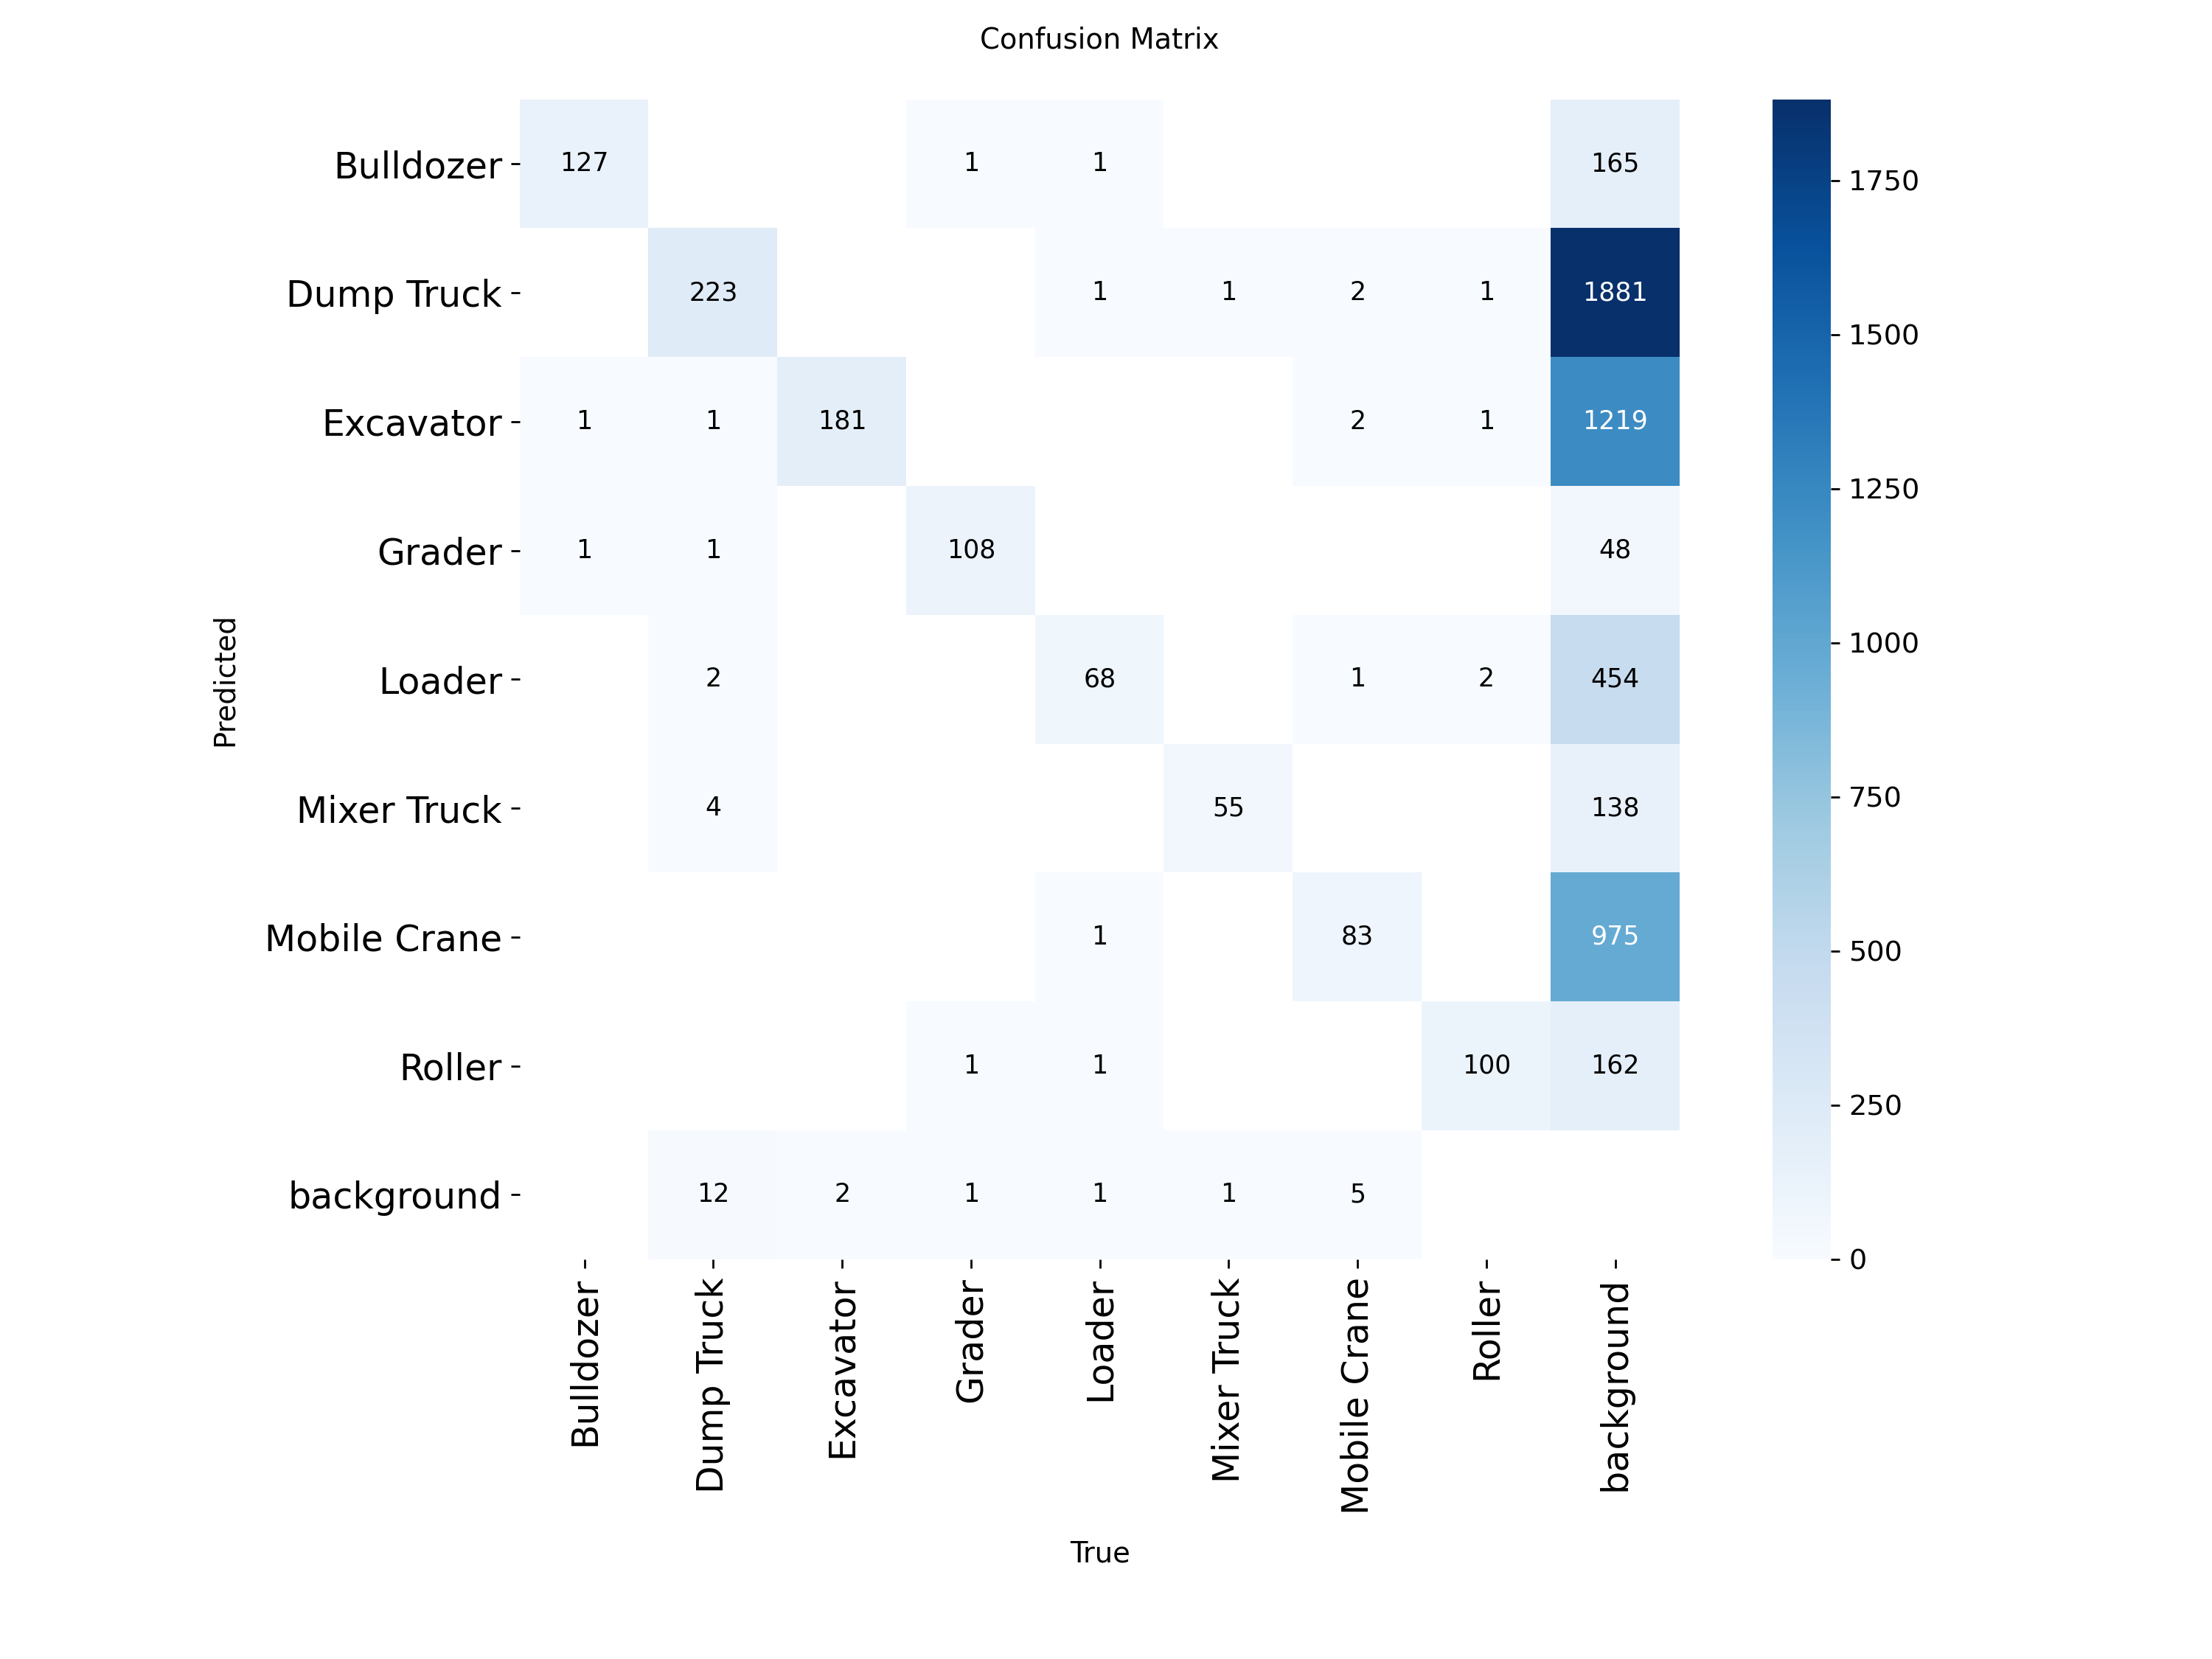

In [17]:
from IPython.display import Image, display
import os

confusion_matrix_path = os.path.join(
    metrics.save_dir,
    "confusion_matrix.png"
)

display(Image(filename=confusion_matrix_path))

In [18]:
import random
import matplotlib.pyplot as plt

# Select 10 random images from the test dataset
selected_images = random.sample(test_images, 10)

# Run prediction
results_10 = model.predict(
    source=selected_images,
    conf=0.25,
    imgsz=640,
    device=0,
    save=False,
    verbose=False
)

print("Predictions completed on 10 test images!")

Predictions completed on 10 test images!


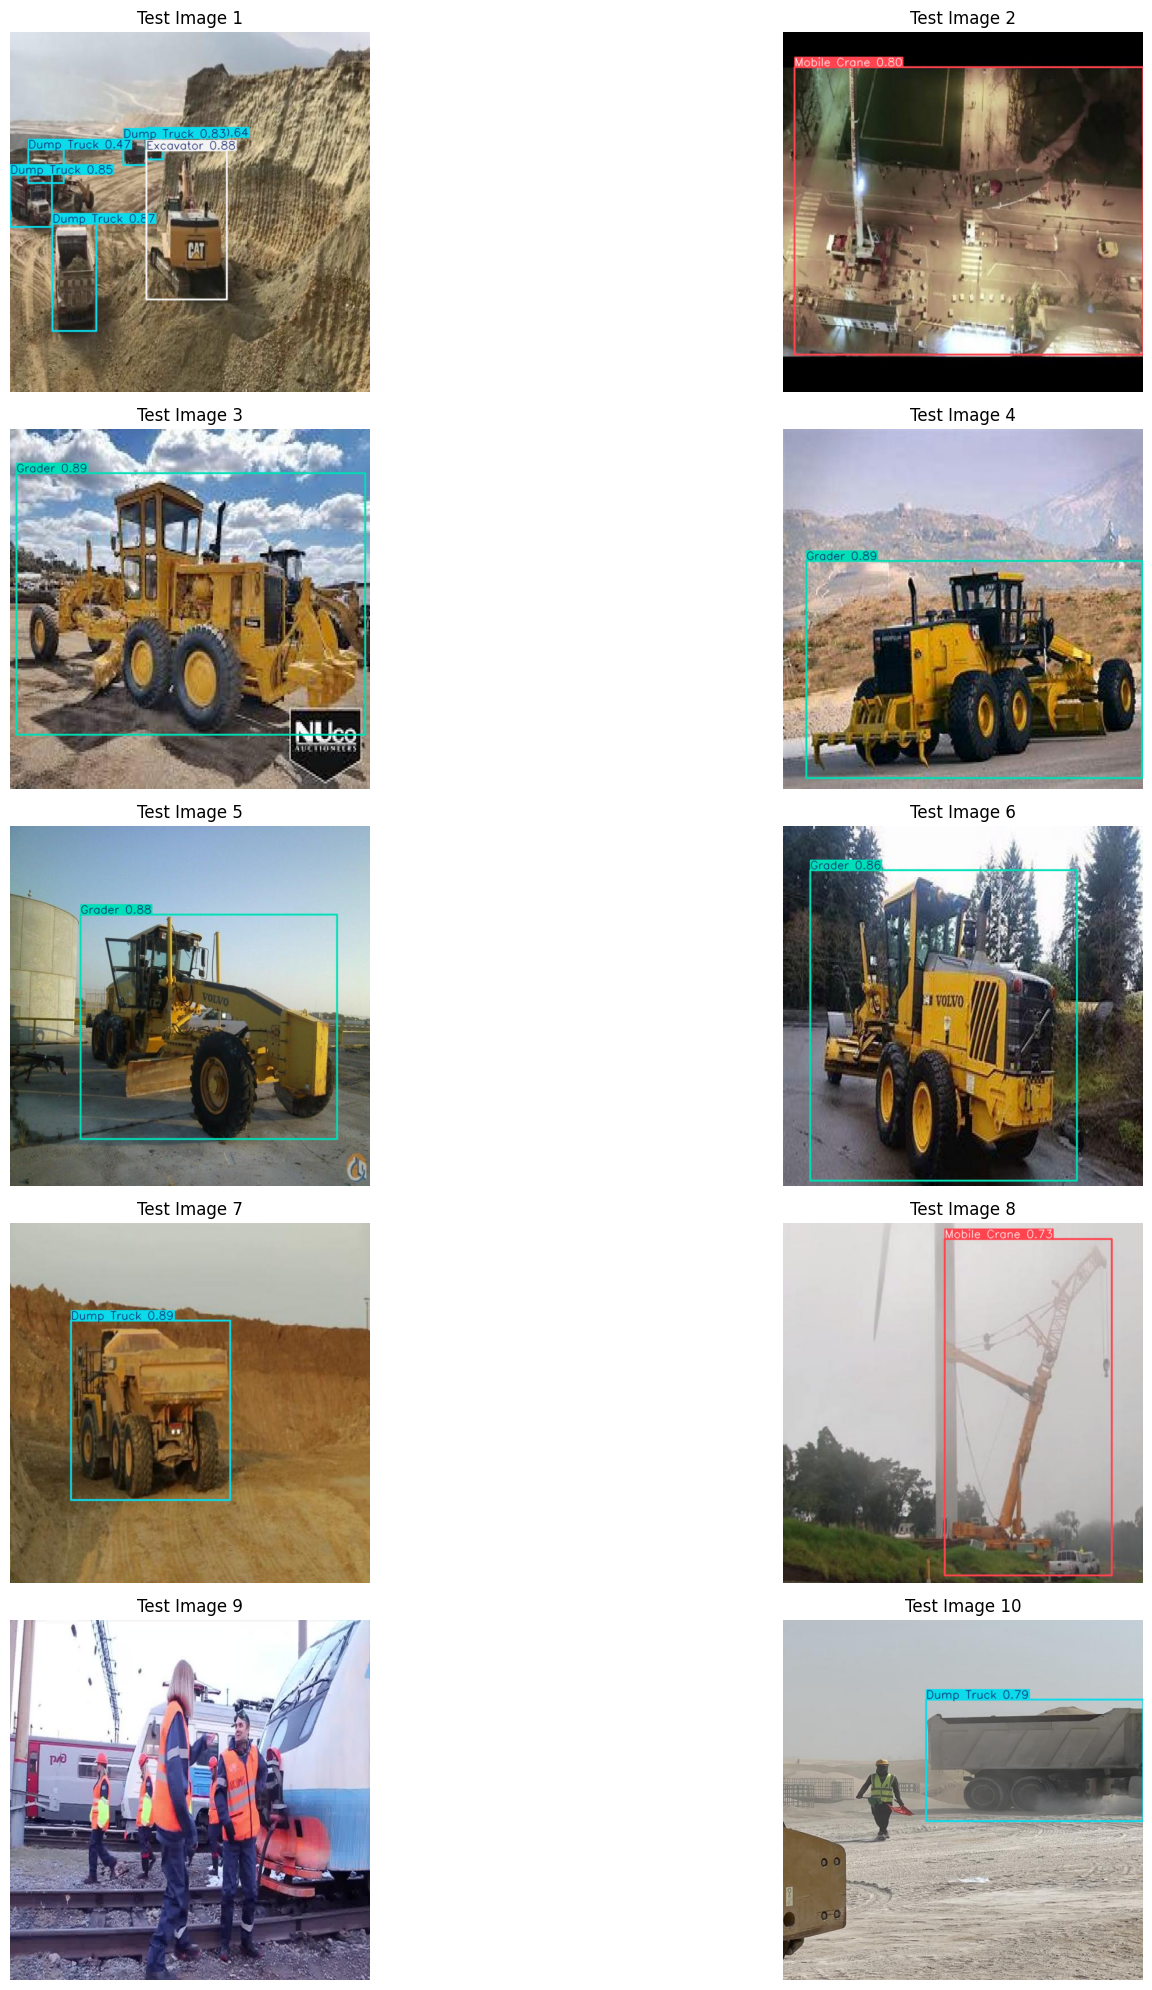

In [19]:
import math

plt.figure(figsize=(20, 20))

for i, result in enumerate(results_10):

    # Get image with bounding boxes and labels
    image = result.plot()

    # Convert BGR to RGB
    image = image[:, :, ::-1]

    plt.subplot(5, 2, i + 1)
    plt.imshow(image)
    plt.axis("off")
    plt.title(f"Test Image {i + 1}")

plt.tight_layout()
plt.show()

In [1]:
from IPython.display import display, clear_output
import ipywidgets as widgets
from PIL import Image
import io
import matplotlib.pyplot as plt
import math

# Allow multiple image uploads
upload = widgets.FileUpload(
    accept="image/*",
    multiple=True,
    description="Upload Images"
)

output = widgets.Output()

def predict_uploaded_images(change):

    with output:
        clear_output(wait=True)

        uploaded_files = upload.value

        if not uploaded_files:
            return

        # Handle uploaded files
        if isinstance(uploaded_files, dict):
            files = list(uploaded_files.values())
        else:
            files = list(uploaded_files)

        print("Total uploaded images:", len(files))

        images = []

        for file in files:
            image = Image.open(
                io.BytesIO(file["content"])
            ).convert("RGB")

            images.append(image)

        # Run prediction on all uploaded images
        results = model.predict(
            source=images,
            conf=0.25,
            imgsz=640,
            batch=16,
            device=0,
            save=False,
            verbose=False
        )

        print("Prediction completed!\n")

        # Display predictions in a grid
        cols = 2
        rows = math.ceil(len(results) / cols)

        plt.figure(figsize=(16, rows * 6))

        for i, result in enumerate(results):

            predicted_image = result.plot()

            plt.subplot(rows, cols, i + 1)
            plt.imshow(predicted_image[:, :, ::-1])
            plt.axis("off")
            plt.title(f"Image {i + 1}")

        plt.tight_layout()
        plt.show()

        # Display detection details
        for i, result in enumerate(results):

            print(f"\nImage {i + 1}:")

            if len(result.boxes) == 0:
                print("No vehicles detected.")
                continue

            for box in result.boxes:
                class_id = int(box.cls[0])
                confidence = float(box.conf[0])

                print(
                    f"{model.names[class_id]}: "
                    f"{confidence * 100:.2f}% confidence"
                )

upload.observe(predict_uploaded_images, names="value")

display(upload)
display(output)

FileUpload(value=(), accept='image/*', description='Upload Images', multiple=True)

Output()